# <span style="color:#9947dc">HI-Small — Modelling on the subsample (step 4)</span>

**What this notebook is for.** It trains and evaluates the transaction-scoring model: the detection
tool the agents call to decide which transfers become alerts. It uses **only** the subsample built in
step 2 and preprocessed in `notebooks/03_PREPROCESSING.ipynb` (`data/processed/preprocessed/`); no other data is
read.

**Rules from the EDA (`EDA_HI_Small_v2`)** that shape everything below:

| Rule | Why | EDA |
|---|---|---|
| Every metric uses `sample_weight = weight` | the subsample keeps all laundering but ~7% of normal accounts; unweighted rates are several times too high | B2, B19 |
| PR-AUC (always next to the prevalence), precision and recall — never accuracy | laundering is ~0.09% of transfers | B7 |
| Alerts = each day's top *k*% of transfers, not a probability threshold | test prevalence is ~2.7× train, so a threshold picked on validation drifts | B4 |
| Test metrics on rows **dated** 8–10 Sept | earlier rows of schemes moved into test are all laundering, with no normal rows from their days | B4 |
| Train with and without `payment_format`, `snd_new_format_48h` and `conversion_before` | both are generator mechanics, not banking behaviour | B8, B15, B16b |
| Confidence intervals by resampling **sender accounts** | rows of one account are not independent | B4 |
| Fit on rows with a full 48 h history | the first 48 h have incomplete windows | 03 §4 |

**Outputs:** `models/` — `txn_scorer.joblib` (all features), `txn_scorer_no_generator.joblib`,
`test_scores.parquet`, `metrics.json`; `reports/` — `model_findings.md`, `figures/04_pr_curves_test.png`.

**Contents:** 0 setup · 1 the data the model sees · 2 single features · 3 choosing the LightGBM set-up
on validation · 4 final models · 5 test PR-AUC · 6 alerts · 7 what gets caught · 8 group-split
robustness · 9 why the model alerts · 10 save · 11 findings.

## <span style="color:#9947dc">0. Setup</span>

Settings you may want to change:
- `BUDGET` — main alert budget: share of each day's transfers that become alerts (0.5% ≈ 5× the
  laundering rate). `BUDGETS` are reported too.
- `BOOT_B` — bootstrap resamples for confidence intervals (200 is enough for a report; 50 for a quick run).
- `GRID` — LightGBM shapes tried on validation.

In [15]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_root(start: Path) -> Path:
    """The aml_pipeline folder (the one holding src/), from its subfolders or from above it."""
    for p in [start, *start.parents, start / "aml_pipeline"]:
        if (p / "src" / "eda_utils.py").is_file():
            return p
    raise FileNotFoundError("open this notebook from inside the aml_pipeline folder")


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))
import evaluation as E          # weighted metrics, budgets, bootstrap (shared with the old pipeline)
import sample_modeling as SM    # data loading, models, alerts, bundle (pickled classes live here)

PRE = ROOT / "data" / "processed" / "preprocessed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports"
BUDGET = 0.005
BUDGETS = (0.001, 0.0025, 0.005, 0.01, 0.02)
BOOT_B = 200
SEED = 0
GRID = [dict(num_leaves=nl, min_child_samples=mcs) for nl in (15, 31, 63) for mcs in (20, 100)]
WEIGHTINGS = ("none", "sample")          # sample_sqrt dropped: it stopped after 1 tree on the real data
WARMUPS = (48, 24)                       # hours of history a fit row needs (48 = complete 48 h windows)
FOLDS = [("2022-09-04", "2022-09-05"),   # (fit on train rows dated up to, validate on rows dated)
         ("2022-09-05", "2022-09-06"),
         ("2022-09-06", "2022-09-07")]
SEEDS = (0, 1, 2, 3, 4)                  # final LightGBM models = average of 5 seeds
NON_ACH_SHARES = (0.0, 0.1, 0.2, 0.3)    # share of the daily alert budget reserved for non-ACH rows
NEW_FEATURES = ["snd_cpty_6h", "rcv_cpty_6h", "snd_in_cpty_48h", "rcv_out_cpty_48h", "sg_paths_48h",
                "cycle3_48h", "snd_recv_usd_24h", "snd_amt_vs_mean_48h", "snd_new_format_48h"]   # EDA B16b
PUBLISHED_F1 = {"GIN": 28.70, "PNA": 56.77, "GFP + LightGBM": 62.86, "GFP + XGBoost": 63.23}  # Altman et al. 2023

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 170, "display.max_columns", 40, "display.max_colwidth", 80)
PURPLE, LILAC, GREY = "#9947dc", "#c9a6ef", "#8a8a8a"
T0 = time.time()

if not (PRE / "artifacts.json").exists():
    raise FileNotFoundError(f"{PRE} not found - run notebooks/03_PREPROCESSING.ipynb first.")
art = SM.load_artifacts(PRE)
D = SM.load_splits(PRE, art)
SETS = SM.feature_sets(art)
missing_new = sorted(set(NEW_FEATURES) - set(art["features"]))
assert not missing_new, f"re-run 03_PREPROCESSING: features missing {missing_new}"
# Main sets = the 31 features without the nine EDA B16b graph / behaviour features: on the real data the
# B16b features did not improve test PR-AUC or F1 (first v4 run: 0.526 with vs 0.537 without), so they are
# kept only as an ablation ("graph_*").
SETS["graph_all"], SETS["graph_no_generator"] = SETS["all"], SETS["no_generator"]
for k in ("all", "no_format", "no_generator"):
    SETS[k] = [f for f in SETS[k] if f not in NEW_FEATURES]
T_START = min(d.meta["Timestamp"].min() for d in D.values()).normalize()
print(f"preprocessed on {art['created']} | history from: {art['settings']['history_from']} | "
      f"{len(art['features'])} features")
print({k: len(v) for k, v in SETS.items()})

preprocessed on 2026-11-12 11:34:41 | history from: full | 40 features
{'all': 31, 'no_format': 30, 'no_generator': 29, 'graph_all': 40, 'graph_no_generator': 37}


## <span style="color:#9947dc">1. The data the model sees</span>

**Why.** Before training, check what each split contains, raw and weighted. The raw laundering rate of
the subsample is several times the real one (EDA B2); the weighted rate is the estimate of the real
rate and is the baseline every PR-AUC must be compared with.

**Fit rows** = train split, full 48 h history, reachable (1.1). **Evaluation rows** = rows dated inside
the split, reachable.

In [16]:
rows = []
for s, d in D.items():
    m = d.meta
    fit, ev = SM.fit_mask(d), SM.eval_mask(d, s)
    rows.append({
        "split": s, "rows": len(d), "laundering": int(d.y.sum()),
        "raw rate %": 100 * d.y.mean(), "weighted rate %": 100 * np.average(d.y, weights=d.w),
        "weighted rows (≈ real transfers)": d.w.sum(),
        "moved-in rows": int(m["scheme_moved"].sum()),
        "fit rows": int(fit.sum()) if s == "train" else np.nan,
        "evaluation rows": int(ev.sum()), "evaluation laundering": int(d.y[ev].sum()),
        "evaluation weighted rate %": 100 * np.average(d.y[ev], weights=d.w[ev]),
    })
overview = pd.DataFrame(rows).set_index("split")
display(overview.round(4))

TR = D["train"].subset(SM.fit_mask(D["train"]))
VA = D["val"].subset(SM.eval_mask(D["val"], "val"))
TE = D["test"].subset(SM.eval_mask(D["test"], "test"))
print(f"fit on {len(TR):,} train rows ({int(TR.y.sum()):,} laundering); "
      f"validate on {len(VA):,} ({int(VA.y.sum()):,}); test on {len(TE):,} ({int(TE.y.sum()):,})")

,rows,laundering,raw rate %,weighted rate %,weighted rows (≈ real transfers),moved-in rows,fit rows,evaluation rows,evaluation laundering,evaluation weighted rate %
split,,,,,,,,,,
train,419472,1989,0.4742,0.0741,2.685618e+06,0,211415.0,419472,1989,0.0741
val,73848,323,0.4374,0.0685,4.717861e+05,94,NaN,73754,229,0.0485
test,206026,2202,1.0688,0.1678,1.312003e+06,709,NaN,205317,1493,0.1139


fit on 211,415 train rows (1,277 laundering); validate on 73,754 (229); test on 205,317 (1,493)


### <span style="color:#9947dc">1.1 A sampling artefact: rows with no seed on either side</span>

**Why.** The sampler never picks hub accounts as seeds, and keeps a row only if one side is a seed —
*or if the row is laundering* (laundering rows are always kept). So a **normal** transfer between two
non-seed accounts (in practice: two hubs) can never be in the subsample, but a **laundering** one
always is. In the subsample those rows are therefore 100% laundering, which a model would learn
("hub to hub = laundering") and which the weights cannot correct (their normal counterparts have no
row to carry the weight).

**Decision.** These rows are left out of fitting and of the weighted metrics; how many laundering
rows that removes, and whether the model still flags them, is reported in section 7.

In [17]:
art_rows = []
for s, d in D.items():
    un = ~d.meta["reachable"].to_numpy(bool)
    art_rows.append({"split": s, "rows with no seed side": int(un.sum()),
                     "of which laundering": int(d.y[un].sum()),
                     "share of the split's laundering %": 100 * d.y[un].sum() / max(d.y.sum(), 1),
                     "both sides hubs": int(((d.X["snd_hub"] == 1) & (d.X["rcv_hub"] == 1)).to_numpy()[un].sum())})
display(pd.DataFrame(art_rows).set_index("split").round(2))

,rows with no seed side,of which laundering,share of the split's laundering %,both sides hubs
split,,,,
train,0,0,0.0,0
val,0,0,0.0,0
test,0,0,0.0,0


## <span style="color:#9947dc">2. Single features — the bar to beat</span>

**Why.** EDA B17 ranked single features on the train split. Here the same ranking on the fit rows,
weighted: each numeric or 0/1 feature used alone as a score (direction chosen on train). The best one
becomes the **rule baseline**; any model has to beat it.

**What to look for.** `conversion_before`, the pair features and the sender's history near the top
(EDA B17); `cross_bank` near "lift 1" (it flags most rows).

In [18]:
g = art["feature_groups"]
single = SM.single_feature_table(TR, VA, g["count"] + g["time"] + g["flag"] + g["amount"])
display(single.round(5))
rule = SM.fit_rule(single)
print(f"rule baseline: {rule.feature} ({'higher' if rule.sign > 0 else 'lower'} = riskier)")

,feature,direction,train_ap,train_lift,val_ap,val_lift
0,cycle3_48h,higher,0.00873,9.18901,0.01267,26.08950
1,reverse_pair_48h,higher,0.00585,6.15972,0.00456,9.39864
2,snd_sent_48h,lower,0.00460,4.84639,0.00429,8.84053
3,snd_cpty_48h,lower,0.00428,4.50487,0.00389,8.00482
4,pair_prev_48h,lower,0.00401,4.22032,0.00401,8.26550
5,new_pair_48h,higher,0.00383,4.03283,0.00377,7.75630
6,conversion_before,higher,0.00366,3.85141,0.00077,1.59303
7,log_amount_usd,higher,0.00358,3.77119,0.00072,1.48043
8,snd_sent_24h,lower,0.00272,2.86460,0.00127,2.61387
9,snd_quiet_48h,higher,0.00255,2.68419,0.00158,3.24630


rule baseline: cycle3_48h (higher = riskier)


## <span style="color:#9947dc">3. Choosing the set-up on rolling validation folds</span>

**Why.** One validation day has only a couple of hundred laundering rows, so differences between set-ups
are mostly noise. Three folds instead, each fitting on earlier days and validating on the next one
(train 1–4 → 5 Sept, 1–5 → 6 Sept, 1–6 → 7 Sept); a set-up is judged on its **mean** weighted
PR-AUC over the folds. Test is never used.

Choices, in two stages:
1. **Warm-up × training weighting.** Warm-up: fit only on rows with 48 h of history (complete windows),
   or already from 24 h (more laundering rows, but their 48 h counts are partly empty). Weighting:
   `none` (each subsample row once, acts as undersampling) or `sample` (true class balance).
2. **Tree shape** (`GRID`) with the winner of stage 1.

Folds share days and schemes, so they are not independent; they only rank set-ups.

In [19]:
TRVA = SM.Data(pd.concat([D["train"].X, D["val"].X], ignore_index=True),
               np.concatenate([D["train"].y, D["val"].y]), np.concatenate([D["train"].w, D["val"].w]),
               pd.concat([D["train"].meta, D["val"].meta], ignore_index=True))
DAY = TRVA.meta["Timestamp"].dt.normalize()
OWN = TRVA.meta["own_date_split"].astype(str).to_numpy()
SPL = TRVA.meta["split"].astype(str).to_numpy()
REACH = TRVA.meta["reachable"].to_numpy(bool)


def fold(fit_end, val_day, warmup):
    fit = (SPL == "train") & (DAY <= pd.Timestamp(fit_end)).to_numpy() & SM.fit_mask(TRVA, warmup, T_START)
    val = (DAY == pd.Timestamp(val_day)).to_numpy() & REACH & (OWN == ("val" if val_day == "2022-09-07" else "train"))
    return TRVA.subset(fit), TRVA.subset(val)


def cv_score(feats, warmup, weighting, params=None, seed=SEED):
    aps = []
    for fit_end, val_day in FOLDS:
        ftr, fva = fold(fit_end, val_day, warmup)
        m = SM.fit_lgbm(ftr, fva, feats, art, weighting=weighting, params=params, seed=seed)
        aps.append(SM.weighted_ap(fva.y, m.predict_score(fva.X), fva.w))
    return float(np.mean(aps)), aps


feats = SETS["all"]
rows = []
for wu in WARMUPS:
    for wt in WEIGHTINGS:
        mean_ap, aps = cv_score(feats, wu, wt)
        rows.append({"warmup_h": wu, "weighting": wt, "cv_pr_auc": mean_ap, **{f"fold_{k + 1}": a for k, a in enumerate(aps)}})
        print(rows[-1], flush=True)
stage1 = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
WARMUP, WEIGHTING = int(stage1.loc[0, "warmup_h"]), stage1.loc[0, "weighting"]

rows = []
for prm in GRID:
    mean_ap, aps = cv_score(feats, WARMUP, WEIGHTING, params=prm)
    rows.append({**prm, "cv_pr_auc": mean_ap, **{f"fold_{k + 1}": a for k, a in enumerate(aps)}})
grid = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
PARAMS = {k: int(grid.loc[0, k]) for k in ("num_leaves", "min_child_samples")}
display(stage1.round(4)); display(grid.round(4))
print(f"-> chosen: warm-up {WARMUP} h, weighting = {WEIGHTING}, {PARAMS}; CV PR-AUC spread over the grid "
      f"{grid.cv_pr_auc.min():.4f}-{grid.cv_pr_auc.max():.4f} (differences this small are noise)")
print(f"[{time.time() - T0:5.0f}s] set-up chosen")

{'warmup_h': 48, 'weighting': 'none', 'cv_pr_auc': 0.27152687668845393, 'fold_1': 0.19846898065810578, 'fold_2': 0.35840920273887283, 'fold_3': 0.25770244666838316}
{'warmup_h': 48, 'weighting': 'sample', 'cv_pr_auc': 0.25118163143708466, 'fold_1': 0.1593924004883127, 'fold_2': 0.3359601697718782, 'fold_3': 0.258192324051063}
{'warmup_h': 24, 'weighting': 'none', 'cv_pr_auc': 0.2744642937768956, 'fold_1': 0.2467126813219947, 'fold_2': 0.3422856635359731, 'fold_3': 0.23439453647271877}
{'warmup_h': 24, 'weighting': 'sample', 'cv_pr_auc': 0.2784676312625632, 'fold_1': 0.2577773086057252, 'fold_2': 0.34357044563034417, 'fold_3': 0.23405513955162016}


,warmup_h,weighting,cv_pr_auc,fold_1,fold_2,fold_3
0,24,sample,0.2785,0.2578,0.3436,0.2341
1,24,none,0.2745,0.2467,0.3423,0.2344
2,48,none,0.2715,0.1985,0.3584,0.2577
3,48,sample,0.2512,0.1594,0.3360,0.2582


,num_leaves,min_child_samples,cv_pr_auc,fold_1,fold_2,fold_3
0,15,20,0.2823,0.2654,0.3496,0.2318
1,31,100,0.2806,0.2668,0.3369,0.2380
2,15,100,0.2800,0.2585,0.3388,0.2425
3,63,20,0.2795,0.2590,0.3368,0.2427
4,63,100,0.2793,0.2682,0.3339,0.2359
5,31,20,0.2785,0.2578,0.3436,0.2341


-> chosen: warm-up 24 h, weighting = sample, {'num_leaves': 15, 'min_child_samples': 20}; CV PR-AUC spread over the grid 0.2785-0.2823 (differences this small are noise)
[  355s] set-up chosen


## <span style="color:#9947dc">4. Final models</span>

**Why.** With the set-up fixed, train on all train rows (with the chosen warm-up), early-stopping on 7 Sept:
- **rule** — the best single feature (section 2);
- **logistic regression** — log counts, scaled continuous features, flags, amount in 10 buckets, one-hot
  categories; one of each pair of features correlated above 0.85 on train is dropped;
- **LightGBM**, each an **average of 5 seeds** (row and column subsampling make single fits noisy), on:
  `all` (31 features), `no_format`, `no_generator` (without payment format and `conversion_before`), and
  the same **with** the nine graph / behaviour features of EDA B16b (`graph_all`, `graph_no_generator`,
  40 / 37 features) — the before / after comparison for those features. On the real data they did not
  help (section 6.1), so the main model does not use them.

`no_generator` is the honest number for the report: what the model can do from behaviour a real bank would
see. `all` is the ceiling inside this synthetic data.

In [20]:
TR = D["train"].subset(SM.fit_mask(D["train"], WARMUP, T_START))
print(f"fit rows with a {WARMUP} h warm-up: {len(TR):,} ({int(TR.y.sum()):,} laundering)")
num_cols = [f for f in SETS["graph_all"] if f in g["count"] + g["time"] + g["flag"]]
DROP, pairs = SM.correlated_to_drop(TR.X, num_cols)
print("dropped for logistic regression (correlated > 0.85 on train):", DROP)

MODELS_FIT = {"rule": rule}
for name in ("all", "no_generator"):
    MODELS_FIT[f"logreg_{name}"] = SM.fit_logreg(TR, SETS[name], art, DROP, weighting="sample", seed=SEED)  # chosen for LightGBM does not suit it
for name in ("all", "no_format", "no_generator", "graph_all", "graph_no_generator"):
    MODELS_FIT[f"lgbm_{name}"] = SM.fit_lgbm_seeds(TR, VA, SETS[name], art, weighting=WEIGHTING, params=PARAMS, seeds=SEEDS)
    print(f"[{time.time() - T0:5.0f}s] lgbm_{name} ({len(SETS[name])} features) trained", flush=True)

val_tab = E.compare({k: m.predict_score(VA.X) for k, m in MODELS_FIT.items()}, VA.y, VA.w)
display(val_tab.round(4))

fit rows with a 24 h warm-up: 325,015 (1,672 laundering)
dropped for logistic regression (correlated > 0.85 on train): ['rcv_out_cpty_48h', 'snd_cpty_48h', 'snd_sent_24h', 'snd_in_cpty_48h']
[  429s] lgbm_all (31 features) trained
[  568s] lgbm_no_format (30 features) trained
[  692s] lgbm_no_generator (29 features) trained
[  773s] lgbm_graph_all (40 features) trained
[  922s] lgbm_graph_no_generator (37 features) trained


,model,rows,positives,prevalence,pr_auc,pr_auc_lift,roc_auc
0,lgbm_all,73754,229,0.0005,0.2462,507.1086,0.9732
1,lgbm_graph_all,73754,229,0.0005,0.2439,502.3358,0.9734
2,lgbm_no_format,73754,229,0.0005,0.1821,375.0421,0.9627
3,lgbm_no_generator,73754,229,0.0005,0.1485,305.9338,0.9626
4,lgbm_graph_no_generator,73754,229,0.0005,0.1454,299.5177,0.9631
5,logreg_all,73754,229,0.0005,0.0816,168.0665,0.9637
6,rule,73754,229,0.0005,0.0288,59.2926,0.6597
7,logreg_no_generator,73754,229,0.0005,0.0210,43.3162,0.9370


## <span style="color:#9947dc">5. Test: PR-AUC</span>

**Why.** Test = rows dated 8–10 Sept, scored once. PR-AUC is shown next to the weighted prevalence
(a useless model scores the prevalence) with a 95% interval from resampling sender accounts.

The last line shows what happens if the weights are forgotten — the number a careless reader would
report (EDA B2).

,model,rows,positives,prevalence,pr_auc,pr_auc_lift,roc_auc,pr_auc_95ci
0,lgbm_all,205317,1493,0.0011,0.5482,481.4910,0.9855,0.4660-0.6070
1,lgbm_graph_all,205317,1493,0.0011,0.5321,467.3677,0.9855,0.4546-0.5884
2,lgbm_no_format,205317,1493,0.0011,0.4254,373.6058,0.9722,0.3626-0.4750
3,lgbm_no_generator,205317,1493,0.0011,0.3674,322.6664,0.9721,0.3109-0.4162
4,lgbm_graph_no_generator,205317,1493,0.0011,0.3651,320.6675,0.9732,0.3075-0.4145
5,logreg_all,205317,1493,0.0011,0.2670,234.5479,0.9792,0.2134-0.3157
6,logreg_no_generator,205317,1493,0.0011,0.0439,38.5472,0.9500,
7,rule,205317,1493,0.0011,0.0137,12.0299,0.7329,


lgbm_all without weights (WRONG, for comparison only): 0.6754 at raw prevalence 0.7272%


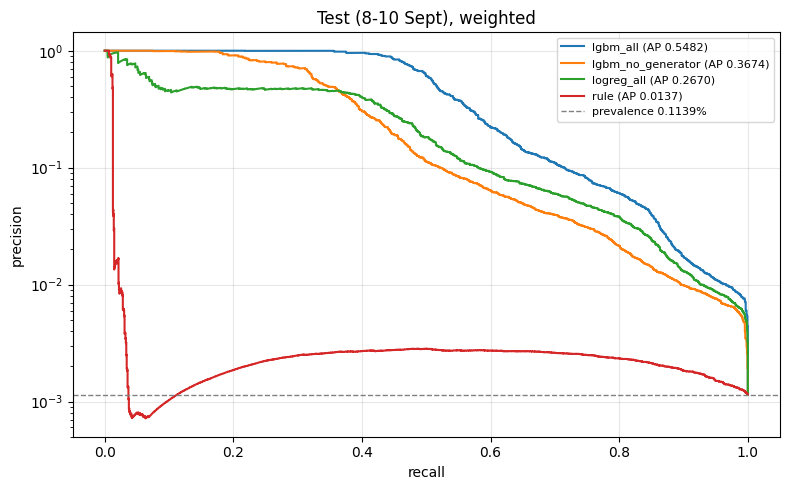

In [21]:
S_TE = {k: m.predict_score(TE.X) for k, m in MODELS_FIT.items()}
test_tab = E.compare(S_TE, TE.y, TE.w)
groups = TE.meta["acct_from"].astype(str).to_numpy()
ci = {}
for k in ("lgbm_all", "lgbm_no_format", "lgbm_no_generator", "lgbm_graph_all", "lgbm_graph_no_generator", "logreg_all"):
    ci[k] = E.cluster_bootstrap(TE.y, S_TE[k], TE.w, groups, "pr_auc", B=BOOT_B, seed=SEED)
test_tab["pr_auc_95ci"] = test_tab["model"].map(lambda k: f"{ci[k]['lo']:.4f}-{ci[k]['hi']:.4f}" if k in ci else "")
display(test_tab.round(4))
print(f"lgbm_all without weights (WRONG, for comparison only): "
      f"{SM.weighted_ap(TE.y, S_TE['lgbm_all'], np.ones(len(TE))):.4f} at raw prevalence {TE.y.mean():.4%}")

fig, ax = plt.subplots(figsize=(8, 5))
E.plot_pr(ax, {k: S_TE[k] for k in ("lgbm_all", "lgbm_no_generator", "logreg_all", "rule")}, TE.y, TE.w,
          "Test (8-10 Sept), weighted")
plt.tight_layout()
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(REPORTS / "figures" / "04_pr_curves_test.png", dpi=150)
plt.show()

## <span style="color:#9947dc">6. Alerts</span>

**Why.** An investigation team works through a fixed number of alerts a day. So each day the top
`BUDGET` share of that day's transfers (weighted, i.e. of real transfers) become alerts. Precision =
share of alerts that are laundering; recall = share of laundering that is alerted.

For comparison, the fixed-threshold rule: the score that gives `BUDGET` on validation, applied to
test unchanged. Expect its alert volume to drift away from `BUDGET` (test prevalence is ~2.7× train).

In [22]:
MAIN = "lgbm_all"
day = TE.meta["Timestamp"].dt.date.to_numpy()
n_days = len(set(day))
budgets = {}
for k in ("lgbm_all", "lgbm_no_generator", "logreg_all", "rule"):
    t = E.daily_budget_table(TE.y, S_TE[k], TE.w, day, BUDGETS)
    t.insert(0, "model", k)
    budgets[k] = t
display(pd.concat(budgets.values()).round(4).set_index(["model", "budget"]))

s_val_main = MODELS_FIT[MAIN].predict_score(VA.X)
THR = E.threshold_for_budget(s_val_main, VA.w, BUDGET)
fixed = E.at_threshold(TE.y, S_TE[MAIN], TE.w, THR, n_days)
print(f"fixed threshold from validation ({THR:.4f}): alert rate on test {fixed['alert_rate']:.2%} "
      f"(target {BUDGET:.2%}), precision {fixed['precision']:.2%}, recall {fixed['recall']:.2%}")

ALERTS = {k: SM.apply_thresholds(S_TE[k], day, SM.daily_thresholds(S_TE[k], day, TE.w, BUDGET), np.inf)
          for k in S_TE}
main_ci = {m: E.cluster_bootstrap(TE.y, S_TE[MAIN], TE.w, groups, m, B=BOOT_B, seed=SEED, alert=ALERTS[MAIN])
           for m in ("precision", "recall")}
print(f"{MAIN} at {BUDGET:.1%}/day: precision 95% CI {main_ci['precision']['lo']:.2%}-{main_ci['precision']['hi']:.2%}, "
      f"recall 95% CI {main_ci['recall']['lo']:.2%}-{main_ci['recall']['hi']:.2%}")

pdays = []
for dd in sorted(set(day)):
    k = day == dd
    pdays.append({"day": dd, "weekday": pd.Timestamp(dd).day_name(), "rows": int(k.sum()),
                  "laundering": int(TE.y[k].sum()), **E.at_alerts(TE.y[k], TE.w[k], ALERTS[MAIN][k])})
display(pd.DataFrame(pdays).set_index("day").round(4))

alerts  alert_rate  precision  recall  true_positives      lift  alerts_per_day
model             budget                                                                                 
lgbm_all          0.0010     852      0.0010     0.5552  0.4896             731  487.5996        438.9075
                  0.0025    1311      0.0025     0.2631  0.5794             865  231.0804       1095.9024
                  0.0050    2024      0.0050     0.1483  0.6524             974  130.2763       2188.8330
                  0.0100    3350      0.0100     0.0836  0.7348            1097   73.3874       4376.2697
                  0.0200    5926      0.0200     0.0464  0.8158            1218   40.7634       8747.7415
lgbm_no_generator 0.0010     714      0.0010     0.4162  0.3670             548  365.5509        438.8860
                  0.0025    1172      0.0025     0.2020  0.4447             664  177.4157       1095.7082
                  0.0050    1891      0.0050     0.1164  0.5117             764  102.1905       2188.7786
                  0.0100    3206      0.0100     0.0682  0.5995             895   59.9340       4371.8822
                  0.0200    5554      0.0200     0.0401  0.7040            1051   35.1764       8747.2280
logreg_all        0.0010     674      0.0010     0.3869  0.3409             509  339.8477        438.4827
                  0.0025    1186      0.0025     0.2156  0.4756             710  189.4041       1097.4580
                  0.0050    1806      0.0050     0.1243  0.5466             816  109.1421       2188.8538
                  0.0100    3057      0.0100     0.0736  0.6470             966   64.6223       4376.3685
                  0.0200    5447      0.0200     0.0436  0.7669            1145   38.3265       8746.3093
rule              0.0010     222      0.0010     0.0167  0.0147              22   14.6608        439.3244
                  0.0025     542      0.0025     0.0097  0.0214              32    8.5224       1099.2714
                  0.0050    1067      0.0050     0.0065  0.0288              43    5.7432       2191.9802
                  0.0100    2100      0.0100     0.0037  0.0322              48    3.2134       4373.1094
                  0.0200    4125      0.0200     0.0019  0.0342              51    1.7072       8745.8380

fixed threshold from validation (0.0155): alert rate on test 0.77% (target 0.50%), precision 10.44%, recall 70.60%
lgbm_all at 0.5%/day: precision 95% CI 13.21%-16.53%, recall 95% CI 56.37%-72.81%


,weekday,rows,laundering,alerts,alert_rate,precision,recall,true_positives,lift
day,,,,,,,,,
2022-09-08,Thursday,73930,539,757,0.005,0.1589,0.6957,375,138.7066
2022-09-09,Friday,99140,513,829,0.005,0.0968,0.6023,309,120.4425
2022-09-10,Saturday,32247,441,438,0.005,0.2860,0.6576,290,131.2737


### <span style="color:#9947dc">6.1 Best F1, operating points, the non-ACH blind spot, and what the new features add</span>

- **Best F1** (weighted, best threshold on test) — the measure the IBM paper reports (minority-class F1).
  It is shown next to the published HI-Small results for orientation only: their split (60/20/20 by
  time on the full file), their features (graph features over the whole graph) and their threshold
  choice differ from ours.
- **Operating points** — precision / recall / alerts per day at 0.1%, 0.25% and 0.5% a day.
- **Non-ACH budget** — the model ranks almost only ACH transfers at the top, so laundering paid by
  cheque, card, cash or Bitcoin is never alerted. Reserving part of each day's budget for non-ACH rows
  trades a little overall precision for recall on those formats.
- **Before / after** — the same set-up with and without the nine EDA B16b features.

In [23]:
f1 = pd.DataFrame({k: SM.best_f1(TE.y, S_TE[k], TE.w) for k in
                   ("lgbm_all", "lgbm_no_generator", "lgbm_graph_all", "lgbm_graph_no_generator", "logreg_all")}).T
f1["f1_pct"] = 100 * f1["f1"]
display(f1.round(4))
print("Published HI-Small minority-class F1 % (Altman et al., NeurIPS 2023):", PUBLISHED_F1)

ops = budgets[MAIN].set_index("budget").loc[[0.001, 0.0025, 0.005], ["alerts_per_day", "precision", "recall"]]
ops_ng = budgets["lgbm_no_generator"].set_index("budget").loc[[0.001, 0.0025, 0.005], ["precision", "recall"]]
OPS = pd.concat({MAIN: ops, "lgbm_no_generator": ops_ng}, axis=1)
display(OPS.round(4))

fmt = TE.meta["Payment Format"].astype(str).to_numpy()
non_ach = fmt != "ACH"
rows = []
for share in NON_ACH_SHARES:
    a = ALERTS[MAIN] if share == 0 else SM.split_budget_alerts(S_TE[MAIN], day, TE.w, non_ach, BUDGET, share)
    r = E.at_alerts(TE.y, TE.w, a)
    rows.append({"non_ach_share_of_budget": share, "precision": r["precision"], "recall": r["recall"],
                 "recall_ACH": TE.y[a & ~non_ach].sum() / max(TE.y[~non_ach].sum(), 1),
                 "recall_non_ACH": TE.y[a & non_ach].sum() / max(TE.y[non_ach].sum(), 1)})
NONACH = pd.DataFrame(rows)
print(f"{MAIN} at {BUDGET:.1%}/day with part of the budget reserved for non-ACH rows "
      f"({int(TE.y[non_ach].sum())} non-ACH laundering rows in test):")
display(NONACH.round(4))

ba = test_tab.set_index("model")
BEFORE_AFTER = pd.DataFrame({
    "features": ["all", "no_generator"],
    "PR-AUC without B16b": [ba.loc["lgbm_all", "pr_auc"], ba.loc["lgbm_no_generator", "pr_auc"]],
    "PR-AUC with B16b": [ba.loc["lgbm_graph_all", "pr_auc"], ba.loc["lgbm_graph_no_generator", "pr_auc"]],
    "best F1 without": [f1.loc["lgbm_all", "f1"], f1.loc["lgbm_no_generator", "f1"]],
    "best F1 with": [f1.loc["lgbm_graph_all", "f1"], f1.loc["lgbm_graph_no_generator", "f1"]],
})
display(BEFORE_AFTER.round(4))

,f1,precision,recall,threshold,f1_pct
lgbm_all,0.5939,0.8938,0.4447,0.2012,59.3942
lgbm_no_generator,0.4330,0.7099,0.3115,0.1216,43.2961
lgbm_graph_all,0.5764,0.8630,0.4327,0.1957,57.6388
lgbm_graph_no_generator,0.4251,0.6124,0.3255,0.1015,42.5079
logreg_all,0.4070,0.4265,0.3891,0.9234,40.6967


Published HI-Small minority-class F1 % (Altman et al., NeurIPS 2023): {'GIN': 28.7, 'PNA': 56.77, 'GFP + LightGBM': 62.86, 'GFP + XGBoost': 63.23}


lgbm_all                   lgbm_no_generator        
       alerts_per_day precision  recall         precision  recall
budget                                                           
0.0010       438.9075    0.5552  0.4896            0.4162  0.3670
0.0025      1095.9024    0.2631  0.5794            0.2020  0.4447
0.0050      2188.8330    0.1483  0.6524            0.1164  0.5117

lgbm_all at 0.5%/day with part of the budget reserved for non-ACH rows (196 non-ACH laundering rows in test):


,non_ach_share_of_budget,precision,recall,recall_ACH,recall_non_ACH
0,0.0,0.1483,0.6524,0.7510,0.0000
1,0.1,0.1463,0.6403,0.7340,0.0204
2,0.2,0.1436,0.6276,0.7178,0.0306
3,0.3,0.1419,0.6196,0.7062,0.0459


,features,PR-AUC without B16b,PR-AUC with B16b,best F1 without,best F1 with
0,all,0.5482,0.5321,0.5939,0.5764
1,no_generator,0.3674,0.3651,0.4330,0.4251


### <span style="color:#9947dc">6.2 Experiment: can non-ACH laundering be learned at all?</span>

**Why.** The main model alerts no laundering paid by cheque, card, cash or Bitcoin, and reserving part of the
budget for non-ACH rows did not help (6.1): inside the non-ACH rows the main model's scores do not rank
laundering above normal. Here a separate LightGBM is trained **only on non-ACH rows** (same set-up, without
the payment-format features), and both models are compared on the non-ACH test rows alone.

**How to read it.** PR-AUC near the non-ACH prevalence = no signal. Clearly above it = learnable, and a
second alert stream for non-ACH transfers would be worth building.

In [24]:
def only(d, mask):
    return d.subset(np.asarray(mask, bool))


na_tr = TR.meta["Payment Format"].astype(str).to_numpy() != "ACH"
na_va = VA.meta["Payment Format"].astype(str).to_numpy() != "ACH"
na_te = TE.meta["Payment Format"].astype(str).to_numpy() != "ACH"
feats_na = [f for f in SETS["no_format"]]
print(f"non-ACH rows - fit: {int(na_tr.sum()):,} ({int(TR.y[na_tr].sum())} laundering), "
      f"val: {int(na_va.sum()):,} ({int(VA.y[na_va].sum())}), test: {int(na_te.sum()):,} ({int(TE.y[na_te].sum())})")
m_na = SM.fit_lgbm_seeds(only(TR, na_tr), only(VA, na_va), feats_na, art, weighting=WEIGHTING, params=PARAMS, seeds=SEEDS)
te_na = only(TE, na_te)
s_na = m_na.predict_score(te_na.X)
rows = {}
for name, sc in [("non-ACH-only model", s_na), ("main model", S_TE[MAIN][na_te])]:
    c = E.cluster_bootstrap(te_na.y, sc, te_na.w, te_na.meta["acct_from"].astype(str).to_numpy(), "pr_auc", B=BOOT_B, seed=SEED)
    rows[name] = {"pr_auc": SM.weighted_ap(te_na.y, sc, te_na.w), "pr_auc_95ci": f"{c['lo']:.4f}-{c['hi']:.4f}",
                  "prevalence": np.average(te_na.y, weights=te_na.w), **SM.best_f1(te_na.y, sc, te_na.w)}
NONACH_EXP = pd.DataFrame(rows).T
NONACH_EXP["x_random"] = NONACH_EXP["pr_auc"].astype(float) / NONACH_EXP["prevalence"].astype(float)
display(NONACH_EXP)
imp = m_na.importance().head(8)
print("non-ACH-only model, top features:"); display(imp.round(4))

non-ACH rows - fit: 282,918 (320 laundering), val: 65,010 (72), test: 177,720 (196)


,pr_auc,pr_auc_95ci,prevalence,f1,precision,recall,threshold,x_random
non-ACH-only model,0.001887,0.0015-0.0035,0.000169,0.017154,0.014795,0.020408,0.004545,11.133021
main model,0.002203,0.0017-0.0056,0.000169,0.015364,0.015422,0.015306,0.003552,12.997632


non-ACH-only model, top features:


,feature,gain,gain_share
0,snd_cpty_48h,4413.6436,0.3559
1,snd_sent_48h,1889.7130,0.1524
2,snd_sent_24h,1808.5833,0.1458
3,snd_sent_60m,1436.6902,0.1158
4,log_amount_usd,854.5779,0.0689
5,pair_prev_48h,492.6496,0.0397
6,reverse_pair_48h,220.8695,0.0178
7,rcv_recv_60m,177.9063,0.0143


## <span style="color:#9947dc">7. What gets caught</span>

**Why.** One recall number hides who is missed. Breakdowns at the main budget:
- **explained vs unexplained** laundering (EDA A4: the unexplained rows are isolated transfers — a different population);
- **pattern type** and **payment format**;
- **schemes:** the agent starts an investigation from an alert, so a scheme is *caught* if at least one
  of its transfers dated 8–10 Sept is alerted. Complete schemes and those cut short on 10 Sept
  (`scheme_truncated`) are counted apart. Row recall and the first alerted step only count the rows
  dated 8–10 Sept (rows moved in from earlier days can never alert);
- the **no-seed laundering rows** set aside in 1.1, scored against the same daily thresholds.

In [25]:
meta_te = TE.meta.assign(y=TE.y)
for by in ("explained", "Pattern Type", "Payment Format"):
    t = pd.concat({k: E.recall_breakdown(meta_te, ALERTS[k], by)["recall"]
                   for k in ("lgbm_all", "lgbm_no_format", "lgbm_no_generator")}, axis=1)
    t.insert(0, "laundering rows", E.recall_breakdown(meta_te, ALERTS[MAIN], by)["positives"])
    display(t.round(3))

# schemes: every attempt whose last row falls in test; only rows dated 8-10 Sept can alert
full_te = D["test"]
alert_full = np.zeros(len(full_te), bool)
ev_full = SM.eval_mask(full_te, "test")
alert_full[np.flatnonzero(ev_full)] = ALERTS[MAIN]
sc_rows = []
for k in ("lgbm_all", "lgbm_no_format", "lgbm_no_generator"):
    a = np.zeros(len(full_te), bool)
    a[np.flatnonzero(ev_full)] = ALERTS[k]
    sc = E.scheme_catch(full_te.meta.assign(y=full_te.y)[ev_full], a[ev_full])   # only rows that can alert
    for trunc, grp in sc.groupby("truncated"):
        sc_rows.append({"model": k, "schemes": "truncated" if trunc else "complete", "n": len(grp),
                        "caught": int(grp.caught.sum()), "catch_rate": grp.caught.mean(),
                        "row_recall": grp.rows_alerted.sum() / grp.rows.sum()})
    if k == MAIN:
        SC_MAIN = sc
display(pd.DataFrame(sc_rows).round(3))
display(E.scheme_summary(SC_MAIN).round(3))

# laundering rows with no seed side (left out of the metrics, 1.1)
un = full_te.subset((full_te.meta["own_date_split"].astype(str) == "test").to_numpy() & ~full_te.meta["reachable"].to_numpy(bool))
if len(un):
    d_un = un.meta["Timestamp"].dt.date.to_numpy()
    thr_main = SM.daily_thresholds(S_TE[MAIN], day, TE.w, BUDGET)
    a_un = SM.apply_thresholds(MODELS_FIT[MAIN].predict_score(un.X), d_un, thr_main, np.inf)
    print(f"no-seed rows dated 8-10 Sept: {len(un)} ({int(un.y.sum())} laundering); "
          f"alerted at the same daily thresholds: {int(a_un[un.y == 1].sum())}")
else:
    print("no no-seed rows in the test days")

,laundering rows,lgbm_all,lgbm_no_format,lgbm_no_generator
explained,,,,
True,911,0.942,0.783,0.765
False,582,0.199,0.120,0.115


,laundering rows,lgbm_all,lgbm_no_format,lgbm_no_generator
Pattern Type,,,,
(none),582,0.199,0.120,0.115
GATHER-SCATTER,179,0.961,0.860,0.810
SCATTER-GATHER,170,0.959,0.806,0.794
STACK,161,0.907,0.696,0.689
FAN-OUT,94,0.979,0.777,0.755
CYCLE,92,0.957,0.761,0.804
FAN-IN,91,0.923,0.813,0.802
BIPARTITE,68,0.897,0.691,0.588
RANDOM,56,0.929,0.821,0.857


,laundering rows,lgbm_all,lgbm_no_format,lgbm_no_generator
Payment Format,,,,
ACH,1297,0.751,0.601,0.586
Cheque,90,0.000,0.011,0.011
Credit Card,57,0.000,0.000,0.000
Cash,30,0.000,0.000,0.000
Bitcoin,19,0.000,0.105,0.158


,model,schemes,n,caught,catch_rate,row_recall
0,lgbm_all,complete,107,106,0.991,0.958
1,lgbm_all,truncated,100,97,0.970,0.930
2,lgbm_no_format,complete,107,102,0.953,0.816
3,lgbm_no_format,truncated,100,92,0.920,0.758
4,lgbm_no_generator,complete,107,100,0.935,0.798
5,lgbm_no_generator,truncated,100,92,0.920,0.742


schemes  caught  row_recall  median_first_alert_step  catch_rate
pattern        truncated                                                                  
BIPARTITE      False           12      12       0.880                      0.0       1.000
               True             5       5       0.944                      0.0       1.000
CYCLE          False           19      19       0.981                      0.0       1.000
               True            11      11       0.925                      0.0       1.000
FAN-IN         False           11      11       0.909                      0.0       1.000
               True            13      13       0.931                      0.0       1.000
FAN-OUT        False           12      12       1.000                      0.0       1.000
               True            11      10       0.963                      0.0       0.909
GATHER-SCATTER False           13      13       1.000                      0.0       1.000
               True            26      25       0.946                      0.0       0.962
RANDOM         False           12      11       0.966                      0.0       0.917
               True             9       8       0.889                      0.0       0.889
SCATTER-GATHER False           13      13       0.983                      0.0       1.000
               True            16      16       0.946                      0.0       1.000
STACK          False           15      15       0.942                      0.0       1.000
               True             9       9       0.880                      0.0       1.000

no no-seed rows in the test days


## <span style="color:#9947dc">8. Robustness: the group split</span>

**Why.** The time split asks "does it work on later days?". The group split (`02_subsample_split.py
group`, EDA B4) asks "does it work on accounts and rings it has never seen?": every scheme cluster
and every account sits in one of train / val / test. Same set-up as section 3, refitted. Caps and
category levels were fitted on the time-split train (03), so these numbers carry a small optimism.

In [26]:
ALL = SM.Data(pd.concat([d.X for d in D.values()], ignore_index=True),
              np.concatenate([d.y for d in D.values()]), np.concatenate([d.w for d in D.values()]),
              pd.concat([d.meta for d in D.values()], ignore_index=True))
gsp = ALL.meta["group_split"].astype(str).to_numpy()
reach = ALL.meta["reachable"].to_numpy(bool)
hist = SM.fit_mask(ALL, WARMUP, T_START)
GTR, GVA, GTE = ALL.subset((gsp == "train") & reach & hist), ALL.subset((gsp == "val") & reach), \
    ALL.subset((gsp == "test") & reach)
grows = []
for name in ("all", "no_generator"):
    m = SM.fit_lgbm_seeds(GTR, GVA, SETS[name], art, weighting=WEIGHTING, params=PARAMS, seeds=SEEDS)
    sg = m.predict_score(GTE.X)
    c = E.cluster_bootstrap(GTE.y, sg, GTE.w, GTE.meta["acct_from"].astype(str).to_numpy(), "pr_auc", B=BOOT_B, seed=SEED)
    grows.append({"features": name, "test rows": len(GTE), "laundering": int(GTE.y.sum()),
                  "prevalence": np.average(GTE.y, weights=GTE.w), "pr_auc": SM.weighted_ap(GTE.y, sg, GTE.w),
                  "pr_auc_95ci": f"{c['lo']:.4f}-{c['hi']:.4f}",
                  "time-split pr_auc": test_tab.set_index("model").loc[f"lgbm_{name}", "pr_auc"]})
GROUP_TAB = pd.DataFrame(grows)
display(GROUP_TAB.round(4))

,features,test rows,laundering,prevalence,pr_auc,pr_auc_95ci,time-split pr_auc
0,all,99489,683,0.0011,0.4535,0.3613-0.5413,0.5482
1,no_generator,99489,683,0.0011,0.2659,0.2045-0.3293,0.3674


## <span style="color:#9947dc">9. Why the model alerts</span>

**Why.** The agent has to say *why* a transfer was flagged, and the report has to show the model
uses sensible signals. LightGBM gives exact per-row contributions (SHAP values, in log-odds): positive
pushes towards "laundering". Shown: gain importance, mean |contribution| over the test alerts, and the
top three reasons for a few alerts — the text the agent receives.

**What to look for.** If `payment_format` dominates `lgbm_all`, the "all features" result leans on a
generator artefact — the reason `no_generator` is the number to lead with.

In [27]:
for k in ("lgbm_all", "lgbm_no_generator"):
    m = MODELS_FIT[k]
    contrib = m.contributions(TE.X[ALERTS[k]])
    imp = m.importance().set_index("feature")
    imp["mean_abs_shap_on_alerts"] = contrib.drop(columns="bias").abs().mean()
    print(k); display(imp.head(12).round(4))

ex = np.flatnonzero(ALERTS[MAIN])[:8]
Xex = TE.X.iloc[ex]
reasons = SM.reason_text(MODELS_FIT[MAIN].contributions(Xex), Xex[MODELS_FIT[MAIN].features])
display(pd.DataFrame({"row_id": TE.meta["row_id"].to_numpy()[ex], "laundering": TE.y[ex],
                      "score": S_TE[MAIN][ex].round(4), "top reasons": reasons}))
display(SM.logreg_coefficients(MODELS_FIT["logreg_all"]).head(12).round(3))

lgbm_all


,gain,gain_share,mean_abs_shap_on_alerts
feature,,,
payment_format,21109.6609,0.1709,3.8819
log_amount_usd,20803.0877,0.1684,0.7385
pair_prev_48h,19855.2098,0.1607,1.5263
conversion_before,13115.2503,0.1062,0.5878
new_pair_48h,6332.9299,0.0513,0.3337
snd_cpty_48h,5849.5683,0.0474,0.1230
reverse_pair_48h,5765.4855,0.0467,0.1815
rcv_recv_60m,4625.0256,0.0374,0.2390
snd_sent_48h,3352.2401,0.0271,0.1004


lgbm_no_generator


,gain,gain_share,mean_abs_shap_on_alerts
feature,,,
log_amount_usd,23218.9174,0.1950,1.3246
pair_prev_48h,18969.8043,0.1593,3.0525
reverse_pair_48h,8926.9905,0.0750,0.4388
snd_cpty_48h,7065.2227,0.0593,0.1491
snd_sent_24h,6343.0994,0.0533,0.3200
country_from,5016.7294,0.0421,0.3631
rcv_recv_48h,4736.7003,0.0398,0.1944
rcv_cpty_48h,4368.1487,0.0367,0.3615
snd_sent_48h,4237.9860,0.0356,0.2181


,row_id,laundering,score,top reasons
0,3733095,0,0.0221,"payment_format=ACH (+3.30), pair_prev_48h=0 (+1.43), log_amount_usd=8.066 (+..."
1,3733481,1,0.0580,"payment_format=ACH (+3.69), pair_prev_48h=0 (+1.53), log_amount_usd=8.686 (+..."
2,3733754,0,0.0250,"payment_format=ACH (+3.34), pair_prev_48h=0 (+1.41), log_amount_usd=7.677 (+..."
3,3735217,0,0.0209,"payment_format=ACH (+3.26), pair_prev_48h=0 (+1.35), log_amount_usd=8.453 (+..."
4,3735321,0,0.0201,"payment_format=ACH (+3.13), pair_prev_48h=0 (+1.39), etype_from=Corporation ..."
5,3735490,0,0.0200,"payment_format=ACH (+3.13), pair_prev_48h=0 (+1.38), etype_from=Corporation ..."
6,3737674,1,0.7585,"reverse_pair_48h=1 (+4.72), payment_format=ACH (+3.91), log_amount_usd=9.447..."
7,3740795,0,0.0174,"payment_format=ACH (+3.28), pair_prev_48h=0 (+1.41), log_amount_usd=8.329 (+..."


,term,coef
0,flags__snd_hub,9.616
1,cats__payment_format_ACH,4.057
2,flags__reverse_pair_48h,3.511
3,cats__country_from_Crypto exchange,3.095
4,flags__conversion_before,2.920
5,cats__payment_format_Wire,-2.775
6,cats__payment_currency_Yen,-2.361
7,cats__etype_to_Individual,-2.278
8,cats__country_to_Croatia,-2.155
9,cats__country_to_Slovenia,-1.984


## <span style="color:#9947dc">10. Save</span>

**What is saved** in `models/`:
- `txn_scorer.joblib` (`lgbm_all`) and `txn_scorer_no_generator.joblib` — model, feature list,
  category levels, alert rule (`BUDGET` per day; the validation threshold as fallback), set-up;
- `test_scores.parquet` — every scored test row with each model's score and alert flag (for the
  agent evaluation set);
- `metrics.json` — the numbers in section 11.

Then a round trip: reload the bundle, score test through `score_transactions` (the agent's entry
point) and check it gives the same scores and alerts.

In [28]:
info = {"weighting": WEIGHTING, "warmup_h": WARMUP, "seeds": list(SEEDS), "params": PARAMS, "budget": BUDGET, "trained": time.strftime("%Y-%m-%d %H:%M"),
        "fit_rows": len(TR), "preprocessed": art["created"], "history_from": art["settings"]["history_from"]}
SM.save_bundle(MODELS / "txn_scorer.joblib", MODELS_FIT["lgbm_all"], art, BUDGET, THR, {**info, "features": "all"})
thr_ng = E.threshold_for_budget(MODELS_FIT["lgbm_no_generator"].predict_score(VA.X), VA.w, BUDGET)
SM.save_bundle(MODELS / "txn_scorer_no_generator.joblib", MODELS_FIT["lgbm_no_generator"], art, BUDGET, thr_ng,
               {**info, "features": "no_generator"})

scores = TE.meta[["row_id", "Timestamp", "acct_from", "acct_to", "weight", "explained", "Attempt ID",
                  "Pattern Type", "scheme_truncated"]].copy()
scores["y"] = TE.y
for k in S_TE:
    scores[f"score_{k}"] = S_TE[k]
    scores[f"alert_{k}"] = ALERTS[k]
scores.to_parquet(MODELS / "test_scores.parquet", index=False)

b = SM.load_bundle(MODELS / "txn_scorer.joblib")
X_text = TE.X.copy()
for c in art["feature_groups"]["categorical"]:
    X_text[c] = X_text[c].astype(str)                      # as read straight from the parquet
rt = SM.score_transactions(b, X_text, TE.meta, explain=False)
assert np.allclose(rt["score"].to_numpy(), S_TE[MAIN]) and (rt["alert"].to_numpy() == ALERTS[MAIN]).all()
print("round trip OK: reloaded bundle reproduces test scores and alerts;", len(rt), "rows")
print(SM.score_transactions(b, TE.X.iloc[np.flatnonzero(ALERTS[MAIN])[:3]]).to_string())

round trip OK: reloaded bundle reproduces test scores and alerts; 205317 rows
        score  alert                                                                            reasons
214  0.022058   True  payment_format=ACH (+3.30), pair_prev_48h=0 (+1.43), log_amount_usd=8.066 (+0.55)
261  0.057987   True  payment_format=ACH (+3.69), pair_prev_48h=0 (+1.53), log_amount_usd=8.686 (+0.95)
295  0.024954   True  payment_format=ACH (+3.34), pair_prev_48h=0 (+1.41), log_amount_usd=7.677 (+0.53)


## <span style="color:#9947dc">10b. Limitations (read before quoting any number)</span>

1. **Synthetic data.** IBM's generator writes most scheme steps as ACH and inserts a conversion self-transfer
   before many of them. `lgbm_all` leans on both; `lgbm_no_generator` is the number to lead with.
2. **Laundering outside schemes** (no `Attempt ID`, about 4 in 10 test laundering rows) is caught far less
   often than scheme laundering (section 7). These rows are isolated transfers; nothing in the features
   marks them.
3. **Non-ACH laundering** (cheque, card, cash, Bitcoin) is not alerted by the main model; section 6.2 shows
   whether a separate model can find it.
4. **Unseen accounts.** The group split (section 8) is the honest estimate for rings the model has never
   seen; it is lower than the time split.
5. **Tuning is noisy.** Validation folds hold a few hundred laundering rows each; set-up differences of
   ~0.01 PR-AUC are not meaningful.
6. **Comparison with the IBM paper** (best F1) is indicative only: different split, sample and features.
7. **Self-transfers are not scored**, so the few labelled-laundering self-transfers (03: "scored + self")
   can never alert.
8. **Weighted estimates.** All rates are estimates for the full population from a weighted subsample; the
   bootstrap intervals show their uncertainty.

## <span style="color:#9947dc">11. Findings</span>

Collected from the outputs above (nothing here is typed by hand), saved to `metrics.json`. Use this
table for the report; quote PR-AUC with its prevalence and interval.

In [29]:
tt = test_tab.set_index("model")
mb = budgets[MAIN].set_index("budget").loc[BUDGET]
ng = budgets["lgbm_no_generator"].set_index("budget").loc[BUDGET]
sc = pd.DataFrame(sc_rows).set_index(["model", "schemes"])
findings = [
    ("training rows (fit) / laundering", f"{len(TR):,} / {int(TR.y.sum()):,}"),
    ("chosen set-up (3 rolling folds)", f"warm-up {WARMUP} h, weighting={WEIGHTING}, {PARAMS}, {len(SEEDS)} seeds"),
    ("test rows / laundering / weighted prevalence", f"{len(TE):,} / {int(TE.y.sum()):,} / {np.average(TE.y, weights=TE.w):.4%}"),
    ("PR-AUC lgbm_all (95% CI)", f"{tt.loc['lgbm_all', 'pr_auc']:.4f} ({tt.loc['lgbm_all', 'pr_auc_95ci']})"),
    ("PR-AUC lgbm_no_format", f"{tt.loc['lgbm_no_format', 'pr_auc']:.4f} ({tt.loc['lgbm_no_format', 'pr_auc_95ci']})"),
    ("PR-AUC lgbm_no_generator (95% CI)", f"{tt.loc['lgbm_no_generator', 'pr_auc']:.4f} ({tt.loc['lgbm_no_generator', 'pr_auc_95ci']})"),
    ("PR-AUC WITH the B16b graph features: all / no_generator",
     f"{tt.loc['lgbm_graph_all', 'pr_auc']:.4f} / {tt.loc['lgbm_graph_no_generator', 'pr_auc']:.4f}"),
    ("non-ACH-only model: PR-AUC on non-ACH test rows (prevalence)",
     f"{NONACH_EXP.loc['non-ACH-only model', 'pr_auc']:.4f} vs main model {NONACH_EXP.loc['main model', 'pr_auc']:.4f} "
     f"({NONACH_EXP.loc['main model', 'prevalence']:.4%})"),
    ("best F1 % (weighted): lgbm_all / lgbm_no_generator",
     f"{100 * f1.loc['lgbm_all', 'f1']:.1f} / {100 * f1.loc['lgbm_no_generator', 'f1']:.1f} "
     f"(published HI-Small: GFP+LightGBM {PUBLISHED_F1['GFP + LightGBM']}, PNA {PUBLISHED_F1['PNA']}; different split)"),
    ("lgbm_all at 0.1%/day: alerts per day, precision / recall",
     f"{OPS.loc[0.001, (MAIN, 'alerts_per_day')]:,.0f}, {OPS.loc[0.001, (MAIN, 'precision')]:.2%} / {OPS.loc[0.001, (MAIN, 'recall')]:.2%}"),
    ("lgbm_all at 0.25%/day: precision / recall",
     f"{OPS.loc[0.0025, (MAIN, 'precision')]:.2%} / {OPS.loc[0.0025, (MAIN, 'recall')]:.2%}"),
    ("non-ACH laundering recall: plain budget / 20% of budget reserved",
     f"{NONACH.loc[NONACH.non_ach_share_of_budget == 0.0, 'recall_non_ACH'].iloc[0]:.1%} / "
     f"{NONACH.loc[NONACH.non_ach_share_of_budget == 0.2, 'recall_non_ACH'].iloc[0]:.1%} "
     f"(overall recall {NONACH.loc[NONACH.non_ach_share_of_budget == 0.0, 'recall'].iloc[0]:.1%} -> "
     f"{NONACH.loc[NONACH.non_ach_share_of_budget == 0.2, 'recall'].iloc[0]:.1%})"),
    ("PR-AUC logreg_all / rule", f"{tt.loc['logreg_all', 'pr_auc']:.4f} / {tt.loc['rule', 'pr_auc']:.4f} ({rule.feature})"),
    (f"lgbm_all at {BUDGET:.1%}/day: alerts per day", f"{mb['alerts_per_day']:,.0f}"),
    (f"lgbm_all at {BUDGET:.1%}/day: precision / recall",
     f"{mb['precision']:.2%} ({main_ci['precision']['lo']:.2%}-{main_ci['precision']['hi']:.2%}) / "
     f"{mb['recall']:.2%} ({main_ci['recall']['lo']:.2%}-{main_ci['recall']['hi']:.2%})"),
    (f"lgbm_no_generator at {BUDGET:.1%}/day: precision / recall", f"{ng['precision']:.2%} / {ng['recall']:.2%}"),
    ("fixed validation threshold: alert rate on test", f"{fixed['alert_rate']:.2%} (target {BUDGET:.2%})"),
    ("complete schemes caught, lgbm_all / lgbm_no_generator",
     " / ".join(f"{int(sc.loc[(k, 'complete'), 'caught'])}/{int(sc.loc[(k, 'complete'), 'n'])} "
                f"({sc.loc[(k, 'complete'), 'catch_rate']:.1%})" if (k, "complete") in sc.index else "n/a"
                for k in ("lgbm_all", "lgbm_no_generator"))),
    ("recall explained / unexplained laundering (lgbm_all)",
     " / ".join(f"{v:.1%}" for v in E.recall_breakdown(meta_te, ALERTS[MAIN], "explained")
                .sort_index(ascending=False)["recall"])),
    ("no-seed laundering rows left out (all splits)", f"{sum(r['of which laundering'] for r in art_rows):,}"),
    ("group split PR-AUC (all / no_generator)", " / ".join(f"{v:.4f}" for v in GROUP_TAB["pr_auc"])),
]
FIND = pd.DataFrame(findings, columns=["finding", "value"]).set_index("finding")
display(FIND)
metrics = {"findings": FIND["value"].to_dict(), "validation": val_tab.to_dict(orient="records"),
           "test": test_tab.to_dict(orient="records"),
           "budgets": {k: v.to_dict(orient="records") for k, v in budgets.items()},
           "per_day": pdays, "schemes": sc_rows, "group_split": GROUP_TAB.to_dict(orient="records"),
           "best_f1": f1.to_dict(orient="index"), "non_ach_budget": NONACH.to_dict(orient="records"),
           "before_after_b16b": BEFORE_AFTER.to_dict(orient="records"), "cv_stage1": stage1.to_dict(orient="records"),
           "setup": info}
(MODELS / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str), encoding="utf-8")


def md_table(df: pd.DataFrame) -> str:
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [str(idx)] + [f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v) for v in row]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


report_md = "\n\n".join([
    "# Model findings (written by notebooks/04_MODELLING.ipynb)",
    f"Trained {info['trained']}. Test = rows dated 8-10 Sept, weighted (estimates on the full population).",
    "## Headline", md_table(FIND),
    "## Test PR-AUC by model", md_table(test_tab.set_index("model")),
    f"## Daily alert budgets ({MAIN})", md_table(budgets[MAIN].set_index("budget")),
    "## Group split (robustness)", md_table(GROUP_TAB.set_index("features")),
    "## Before / after the graph and behaviour features (EDA B16b)", md_table(BEFORE_AFTER.set_index("features")),
    "## Non-ACH share of the alert budget", md_table(NONACH.set_index("non_ach_share_of_budget")),
    "Figures: `figures/04_pr_curves_test.png`, `figures/03_flag_lift_train.png`.",
])
(REPORTS / "model_findings.md").write_text(report_md + "\n", encoding="utf-8")
print("report table ->", REPORTS / "model_findings.md")
print(f"saved -> {MODELS}   [{time.time() - T0:.0f}s total]")

,value
finding,
training rows (fit) / laundering,"325,015 / 1,672"
chosen set-up (3 rolling folds),"warm-up 24 h, weighting=sample, {'num_leaves': 15, 'min_child_samples': 20},..."
test rows / laundering / weighted prevalence,"205,317 / 1,493 / 0.1139%"
PR-AUC lgbm_all (95% CI),0.5482 (0.4660-0.6070)
PR-AUC lgbm_no_format,0.4254 (0.3626-0.4750)
PR-AUC lgbm_no_generator (95% CI),0.3674 (0.3109-0.4162)
PR-AUC WITH the B16b graph features: all / no_generator,0.5321 / 0.3651
non-ACH-only model: PR-AUC on non-ACH test rows (prevalence),0.0019 vs main model 0.0022 (0.0169%)
best F1 % (weighted): lgbm_all / lgbm_no_generator,"59.4 / 43.3 (published HI-Small: GFP+LightGBM 62.86, PNA 56.77; different sp..."


report table -> d:\capstone\aml_pipeline\reports\model_findings.md
saved -> d:\capstone\aml_pipeline\models   [1753s total]
